# Why $J \geq 0.8$ for positives and $J \leq 0.1$ for negatives?

This notebook backs the label thresholds of SQuARE (Section 3 of the paper) with data.
A pair of queries is **positive** if the Jaccard overlap of their answers is $J \geq 0.8$,
**negative** if $J \leq 0.1$, and unlabeled otherwise. The notebook answers four questions:

1. **How is $J$ spread over query pairs?** If most pairs sit near $0$ or near $1$, few labels depend on the exact cutoffs.
2. **What does a label guarantee for result reuse?** For a positive pair, returning one query's answer for the other gives at least 80% correct rows *and* at least 80% of the required rows.
3. **How much do the labels change under other thresholds?** Number of positives, anchors, and the size of the positive components that drive the component-disjoint splits.
4. **(optional) Do the retrieval results depend on the 0.8 cutoff?** Trained encoders are scored on the full test collection with other relevance cutoffs, without retraining.

**Two data modes** (picked automatically per graph):

| mode | needs | covers |
|---|---|---|
| `full` | the execution caches (released separately, not in git): `datasets/<graph>-splits/query_execution_cache.jsonl`, or `$LT_CACHE_DIR/query_execution_cache_<graph>.jsonl` | every pair of the retained queries, every value of $J$ |
| `rq3` | only files in git (`<graph>-{valid,test}-rq3.json`) | every pair of validation and test queries; the exact $J$ is known for $J \leq 0.1$ and $J \geq 0.8$, the unlabeled range is only counted |

Run from anywhere inside the repository:
```bash
export LT_CACHE_DIR=~/Downloads             # folder with query_execution_cache_<graph>.jsonl (optional)
export PYTHONPATH="$PWD/src:$PYTHONPATH"   # only needed for the optional encoder check (Section 5)
jupyter nbconvert --to notebook --execute --inplace scripts/analysis/label_thresholds.ipynb
```
The first `full` run reads each cache once (two passes; the Wikidata file is about 23 GB) and saves the pair
overlaps to `pairs_<graph>.npz`; later runs read only that small file. Outputs go to `results/analysis/label_thresholds/` (CSV tables, PNG/PDF figures, and the paper files
`labelthresholds.tex` + `labelthresholds_numbers.tex`). If the paper folder is found next to the code
(`../current version/Tables/appendix`), the two `.tex` files are copied there as well.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import re
import shutil
import time
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.sparse.csgraph import connected_components

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ----------------------------------------------------------------------------- configuration
GRAPHS = ["dbpedia", "wikidata"]
POS_MIN, NEG_MAX = 0.8, 0.1                     # thresholds used in the paper
POS_GRID = [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]
NEG_GRID = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
MODE = os.environ.get("LT_MODE", "auto")        # "auto" | "full" | "rq3"

# optional Section 5: score trained encoders under other relevance cutoffs (needs results/raw checkpoints)
RUN_MODEL_CHECK = os.environ.get("LT_MODEL_CHECK", "0") == "1"
CHECK_MODELS = ["mpnet", "e5-base-v2", "qwen3-embedding", "codebert"]
CHECK_SEEDS = [42, 43, 44, 45, 46]
CHECK_REL = [0.6, 0.7, 0.8, 0.9, 1.0]           # relevance cutoffs; values < 0.8 need full mode
DEVICE = os.environ.get("LT_DEVICE", "cuda")

GRAPH_NAME = {"dbpedia": "DBpedia", "wikidata": "Wikidata"}
COL = {"neg": "#b2443a", "mid": "#9a9a9a", "pos": "#2f7d4f",          # label bands
       "pairs": "#1f5fa8", "queries": "#d17a00", "comp": "#5b8c2a"}  # sensitivity lines


def find_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "datasets").is_dir():
            return p
    raise SystemExit("Run this notebook inside the SPARQL-Embeddings repository.")


ROOT = find_root(Path.cwd().resolve())
OUT = ROOT / "results" / "analysis" / "label_thresholds"
OUT.mkdir(parents=True, exist_ok=True)
_paper = os.environ.get("LT_PAPER_DIR") or ROOT.parent.parent / "current version" / "Tables" / "appendix"
PAPER_DIR = Path(_paper) if Path(_paper).is_dir() else None
print("outputs  : results/analysis/label_thresholds/")
print("paper dir:", "found, tex files are copied there" if PAPER_DIR else "not found (tex files stay in the outputs folder)")

outputs  : results/analysis/label_thresholds/
paper dir: not found (tex files stay in the outputs folder)


## 1. Load the pair overlaps

`full` mode recomputes $J$ from the cached answer sets exactly as `rebuild_<graph>_clean_splits.py` does
(same query filter, same hashing) and checks the counts against `split_report.json`.
`rq3` mode reads the complete pair labels of the validation and test queries.

In [2]:
try:                                            # orjson parses the large cache lines much faster
    import orjson
    _loads = orjson.loads
except ImportError:
    _loads = json.loads


def normalize_query(q: str) -> str:            # identical to the rebuild scripts and cache_eval
    return re.sub(r"\s+", " ", q.strip())


def query_hash(q: str) -> str:
    return hashlib.sha256(normalize_query(q).encode("utf-8")).hexdigest()


_AGG = re.compile(r"\b(COUNT|SUM|AVG|MIN|MAX|SAMPLE|GROUP_CONCAT)\s*\(", re.I)
_GROUP_BY = re.compile(r"\bGROUP\s+BY\b", re.I)


def is_scalar_aggregate(q: str) -> bool:       # copied from rebuild_wikidata_clean_splits.py
    body = re.sub(r"<[^<>\s]*>", "<>", q)
    if _GROUP_BY.search(body):
        return False
    for m in re.finditer(r"\bSELECT\b(.*?)(\bWHERE\b|\{)", body, re.I | re.S):
        if _AGG.search(m.group(1)):
            return True
    return False


@dataclass
class Pairs:
    """All unordered query pairs of one graph. Pairs with J > 0 are stored explicitly."""
    graph: str
    mode: str
    scope: str
    sizes: np.ndarray            # answer-set size per query
    i: np.ndarray                # pairs with J > 0 (and a known value)
    j: np.ndarray
    J: np.ndarray
    n_zero: int                  # pairs with J = 0
    n_mid_unknown: int = 0       # rq3 mode: pairs with 0.1 < J < 0.8, value not stored
    hashes: list = field(default_factory=list)   # query hash per id (for Section 5)

    @property
    def n_queries(self) -> int:
        return len(self.sizes)

    @property
    def n_pairs(self) -> int:
        return len(self.J) + self.n_zero + self.n_mid_unknown

    @property
    def inter(self) -> np.ndarray:  # |A ∩ B| recovered from J and the two sizes
        s = self.sizes[self.i] + self.sizes[self.j]
        return np.rint(self.J * s / (1.0 + self.J))

    def known(self, lo: float, hi: float) -> bool:
        """True if every J value in [lo, hi] is available in this mode."""
        if self.mode == "full":
            return True
        return hi <= NEG_MAX or lo >= POS_MIN


def cache_path(graph: str) -> Path:
    """Execution cache: $LT_CACHE_DIR/query_execution_cache_<graph>.jsonl, else datasets/<graph>-splits/."""
    d = os.environ.get("LT_CACHE_DIR")
    if d:
        for name in (f"query_execution_cache_{graph}.jsonl", "query_execution_cache.jsonl"):
            if (Path(d).expanduser() / name).exists():
                return Path(d).expanduser() / name
    return ROOT / "datasets" / f"{graph}-splits" / "query_execution_cache.jsonl"


def pair_file(graph: str) -> Path:   # small cache of the pair overlaps, so later runs skip the big file
    return OUT / f"pairs_{graph}.npz"


_HASH_RE = re.compile(rb'"query_hash"\s*:\s*"([0-9a-f]{64})"')


def scan_cache(path: Path, need: set) -> dict:
    """Pass 1: byte offset of the LAST line of every needed query (as load_execution_cache keeps the last)."""
    offsets, pos, t0 = {}, 0, time.time()
    with open(path, "rb") as f:
        for line in f:
            m = _HASH_RE.search(line, 0, 4096) or _HASH_RE.search(line)
            if m and m.group(1).decode() in need:
                offsets[m.group(1).decode()] = pos
            pos += len(line)
    print(f"  scanned {pos / 1e9:.1f} GB in {time.time() - t0:.0f}s, {len(offsets)} needed queries found")
    return offsets


def load_full(graph: str) -> Pairs:
    split_dir = ROOT / "datasets" / f"{graph}-splits"
    report = json.load(open(split_dir / "split_report.json"))
    pf = pair_file(graph)
    if pf.exists() and os.environ.get("LT_REBUILD", "0") != "1":
        z = np.load(pf, allow_pickle=False)
        sizes, i, j, inter, ok = z["sizes"], z["i"], z["j"], z["inter"].astype(np.float64), list(z["hashes"])
        print(f"  {graph}: pair overlaps read from {pf.name} (set LT_REBUILD=1 to recompute)")
    else:
        queries = json.load(open(split_dir / "unique_queries.json"))
        if "excluded_scalar_aggregates" in report:      # Wikidata: filter applied before execution
            queries = [q for q in queries if not is_scalar_aggregate(q)]
        hashes, seen = [], set()
        for q in queries:
            h = query_hash(q)
            if h not in seen:
                seen.add(h)
                hashes.append(h)
        path = cache_path(graph)
        print(f"  {graph}: reading {path} ({path.stat().st_size / 1e9:.1f} GB)")
        offsets = scan_cache(path, set(hashes))
        # Pass 2: parse only the needed lines. Each answer row is mapped to a 64-bit hash, which keeps
        # memory small; a collision between two different rows is very unlikely (~1e-3 expected for 2e8 rows).
        ok, parts, t0 = [], [], time.time()
        with open(path, "rb") as f:
            for n_done, h in enumerate(hashes):
                if h not in offsets:
                    continue
                f.seek(offsets[h])
                o = _loads(f.readline())
                if o.get("status") != "success" or not o.get("answers"):
                    continue
                ok.append(h)
                parts.append(np.fromiter({hash(a) for a in o["answers"]}, dtype=np.int64))
                if n_done % 1000 == 0:
                    print(f"    {n_done}/{len(hashes)} queries, {time.time() - t0:.0f}s")
        sizes = np.array([len(x) for x in parts], dtype=np.int64)
        rows = np.repeat(np.arange(len(parts), dtype=np.int32), sizes)
        vals = np.concatenate(parts)
        del parts
        _, cols, counts = np.unique(vals, return_inverse=True, return_counts=True)
        del vals
        keep = counts[cols] >= 2                       # rows that occur in one query only add no overlap
        rows, cols = rows[keep], cols[keep]
        _, cols = np.unique(cols, return_inverse=True)
        X = sparse.csr_matrix((np.ones(len(rows), dtype=np.int32), (rows, cols)),
                              shape=(len(ok), int(cols.max()) + 1 if len(cols) else 1))
        del rows, cols, keep
        C = sparse.triu(X @ X.T, k=1).tocoo()
        i, j, inter = C.row.astype(np.int64), C.col.astype(np.int64), C.data.astype(np.float64)
        np.savez_compressed(pf, sizes=sizes, i=i, j=j, inter=inter.astype(np.int64), hashes=np.array(ok))
        print(f"  {graph}: pair overlaps saved to {pf.name} ({time.time() - t0:.0f}s)")
    J = inter / (sizes[i] + sizes[j] - inter)
    n = len(ok)
    p = Pairs(graph, "full", "all pairs of the retained queries", sizes, i, j, J,
              n * (n - 1) // 2 - len(J), hashes=ok)
    checks = {"usable_nonempty_queries": (report.get("usable_nonempty_queries"), n),
              "pairs_with_shared_answers": (report.get("pairs_with_shared_answers"), len(J)),
              "positive_edges": (report.get("positive_edges"), int((J >= POS_MIN - 1e-12).sum()))}
    for k, (want, got) in checks.items():
        flag = "ok" if want is None or want == got else "MISMATCH"
        print(f"  {graph:9s} {k:26s} report={want}  recomputed={got}  {flag}")
    return p


def load_rq3(graph: str) -> Pairs:
    sizes, I, Jx, Jv, n_zero, n_mid, hashes = [], [], [], [], 0, 0, []
    for split in ("valid", "test"):
        d = json.load(open(ROOT / "datasets" / f"{graph}-splits" / f"{graph}-{split}-rq3.json"))
        off = len(sizes)
        qs = sorted(d["queries"], key=lambda x: x["id"])
        sizes += [q["n_answers"] for q in qs]
        hashes += [q["query_hash"] for q in qs]
        for a, b, j in d["positive_pairs"] + d["negative_pairs"]:
            if j > 0:
                I.append(a + off); Jx.append(b + off); Jv.append(j)
            else:
                n_zero += 1
        n_mid += d["metadata"]["excluded_intermediate_pair_count"]
        n = len(qs)
        assert d["metadata"]["all_unordered_pair_count"] == n * (n - 1) // 2
    return Pairs(graph, "rq3", "all pairs of validation and test queries", np.array(sizes),
                 np.array(I), np.array(Jx), np.array(Jv, dtype=float), n_zero, n_mid, hashes)


print("LT_CACHE_DIR =", os.environ.get("LT_CACHE_DIR", "(not set)"), "| LT_MODE =", MODE)
PAIRS = {}
for g in GRAPHS:
    cp = cache_path(g)
    has_cache = pair_file(g).exists() or cp.exists()
    print(f"  {g}: cache {cp} -> {'found' if cp.exists() else 'NOT FOUND'}"
          + (f"; saved overlaps {pair_file(g).name} found" if pair_file(g).exists() else ""))
    if MODE == "full" and not has_cache:
        raise FileNotFoundError(f"LT_MODE=full but no execution cache for {g} at {cp}")
    mode = MODE if MODE != "auto" else ("full" if has_cache else "rq3")
    PAIRS[g] = load_full(g) if mode == "full" else load_rq3(g)

pd.DataFrame([{"graph": GRAPH_NAME[g], "mode": p.mode, "scope": p.scope, "queries": p.n_queries,
               "pairs": p.n_pairs, "pairs with J>0": len(p.J) + p.n_mid_unknown}
              for g, p in PAIRS.items()])

LT_CACHE_DIR = (not set) | LT_MODE = full
  dbpedia: cache datasets/dbpedia-splits/query_execution_cache.jsonl -> found; saved overlaps pairs_dbpedia.npz found
  dbpedia: pair overlaps read from pairs_dbpedia.npz (set LT_REBUILD=1 to recompute)
  dbpedia   usable_nonempty_queries    report=4727  recomputed=4727  ok
  dbpedia   pairs_with_shared_answers  report=680949  recomputed=680949  ok
  dbpedia   positive_edges             report=46192  recomputed=46192  ok
  wikidata: cache datasets/wikidata-splits/query_execution_cache.jsonl -> found; saved overlaps pairs_wikidata.npz found
  wikidata: pair overlaps read from pairs_wikidata.npz (set LT_REBUILD=1 to recompute)
  wikidata  usable_nonempty_queries    report=9679  recomputed=9679  ok
  wikidata  pairs_with_shared_answers  report=556599  recomputed=556599  ok
  wikidata  positive_edges             report=20243  recomputed=20243  ok


,graph,mode,scope,queries,pairs,pairs with J>0
0,DBpedia,full,all pairs of the retained queries,4727,11169901,680949
1,Wikidata,full,all pairs of the retained queries,9679,46836681,556599


## 2. How is $J$ spread over query pairs?

If the distribution is strongly two-sided (almost all pairs at $J=0$ or close to $J=1$), the labels
barely move when the cutoffs move. The table counts pairs per band; the figure shows every pair with $J>0$
(log scale, $J=0$ pairs are reported in the box).

In [3]:
def band_counts(p: Pairs) -> dict:
    J = p.J
    mid = int(((J > NEG_MAX) & (J < POS_MIN)).sum()) + p.n_mid_unknown
    near = lambda lo, hi: int(((J >= lo) & (J < hi)).sum()) if p.known(lo, hi) else np.nan
    pos = int((J >= POS_MIN).sum())
    return {
        "pairs": p.n_pairs,
        "J = 0": p.n_zero,
        "0 < J <= 0.1": int(((J > 0) & (J <= NEG_MAX)).sum()),
        "0.1 < J < 0.8": mid,
        "0.8 <= J < 1": int(((J >= POS_MIN) & (J < 1)).sum()),
        "J = 1": int((J >= 1).sum()),
        "positives": pos,
        "negatives": p.n_zero + int(((J > 0) & (J <= NEG_MAX)).sum()),
        "0.7 <= J < 0.8": near(0.7, 0.8),
        "0.8 <= J < 0.9": near(0.8, 0.9),
        "0.1 < J <= 0.2": near(0.1 + 1e-12, 0.2 + 1e-12),
        "0.05 < J <= 0.1": near(0.05 + 1e-12, 0.1 + 1e-12),
    }


bands = pd.DataFrame({GRAPH_NAME[g]: band_counts(p) for g, p in PAIRS.items()}).T
share = bands.div(bands["pairs"], axis=0)
overlap = bands["pairs"] - bands["J = 0"]
summary = pd.DataFrame({
    "pairs": bands["pairs"],
    "% J=0": 100 * share["J = 0"],
    "% labeled": 100 * (bands["positives"] + bands["negatives"]) / bands["pairs"],
    "% unlabeled (of all)": 100 * share["0.1 < J < 0.8"],
    "% unlabeled (of J>0)": 100 * bands["0.1 < J < 0.8"] / overlap,
    "% positives with J=1": 100 * bands["J = 1"] / bands["positives"],
    "% positives with J<0.9": 100 * bands["0.8 <= J < 0.9"] / bands["positives"],
    "% negatives with J>0": 100 * bands["0 < J <= 0.1"] / bands["negatives"],
}).round(2)
bands.to_csv(OUT / "band_counts.csv")
summary.to_csv(OUT / "band_summary.csv")
display(bands)
summary

,pairs,J = 0,0 < J <= 0.1,0.1 < J < 0.8,0.8 <= J < 1,J = 1,positives,negatives,0.7 <= J < 0.8,0.8 <= J < 0.9,0.1 < J <= 0.2,0.05 < J <= 0.1
DBpedia,11169901,10488952,364648,270109,8467,37725,46192,10853600,11176,7758,89402,206927
Wikidata,46836681,46280082,370395,165961,4017,16226,20243,46650477,2609,2307,113910,150787


,pairs,% J=0,% labeled,% unlabeled (of all),% unlabeled (of J>0),% positives with J=1,% positives with J<0.9,% negatives with J>0
DBpedia,11169901,93.90,97.58,2.42,39.67,81.67,16.8,3.36
Wikidata,46836681,98.81,99.65,0.35,29.82,80.16,11.4,0.79


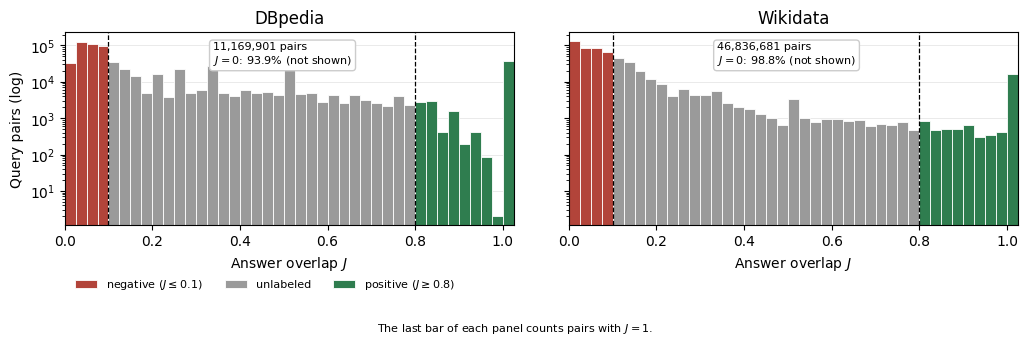

In [4]:
BIN_W = 0.025
EDGES = np.round(np.arange(0, 1 + BIN_W / 2, BIN_W), 6)


def histogram(p: Pairs):
    """Counts of pairs with 0 < J < 1 per bin; J = 1 gets its own last bin.
    Bins are right-closed up to NEG_MAX and left-closed from there on, so J = 0.1 counts as negative
    and J = 0.8 as positive, as in the labels."""
    J = p.J[p.J < 1]
    x = np.round(J / BIN_W, 9)
    k = np.where(J <= NEG_MAX + 1e-12, np.ceil(x) - 1, np.floor(x)).astype(int)
    c = np.bincount(np.clip(k, 0, len(EDGES) - 2), minlength=len(EDGES) - 1)
    return c, int((p.J >= 1).sum())


fig, axes = plt.subplots(1, len(PAIRS), figsize=(5.2 * len(PAIRS), 3.3), sharey=True)
for ax, (g, p) in zip(np.atleast_1d(axes), PAIRS.items()):
    c, n_one = histogram(p)
    left = EDGES[:-1]
    band = np.where(left + BIN_W <= NEG_MAX + 1e-9, "neg", np.where(left >= POS_MIN - 1e-9, "pos", "mid"))
    for b, lab in (("neg", f"negative ($J\\leq{NEG_MAX}$)"), ("mid", "unlabeled"), ("pos", f"positive ($J\\geq{POS_MIN}$)")):
        m = band == b
        ax.bar(left[m], c[m], width=BIN_W, align="edge", color=COL[b], edgecolor="white", linewidth=0.6, label=lab)
    ax.bar([1.0], [n_one], width=BIN_W, align="edge", color=COL["pos"], edgecolor="white", linewidth=0.6)
    for t in (NEG_MAX, POS_MIN):
        ax.axvline(t, color="black", ls="--", lw=0.9)
    ax.set_yscale("log")
    ax.set_xlim(0, 1 + BIN_W)
    ax.set_xlabel("Answer overlap $J$")
    ax.set_title(GRAPH_NAME[g])
    ax.grid(axis="y", color="0.9", lw=0.6)
    ax.set_axisbelow(True)
    zero = 100 * p.n_zero / p.n_pairs
    txt = f"{p.n_pairs:,} pairs\n$J=0$: {zero:.1f}% (not shown)"
    if p.n_mid_unknown:
        txt += f"\n$0.1<J<0.8$: {p.n_mid_unknown:,} pairs\n(values not stored)"
    ax.text(0.33, 0.95, txt, transform=ax.transAxes, va="top", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.8"))
np.atleast_1d(axes)[0].set_ylabel("Query pairs (log)")
fig.text(0.5, -0.02, "The last bar of each panel counts pairs with $J=1$.", ha="center", fontsize=8)
np.atleast_1d(axes)[0].legend(loc="upper left", bbox_to_anchor=(0.0, -0.22), ncol=3, frameon=False, fontsize=8)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"fig_jaccard_distribution.{ext}", dpi=200, bbox_inches="tight")
plt.show()

## 3. What does a label guarantee when one answer is reused for another?

If the answer $B$ of $q_j$ is returned for $q_i$ with answer $A$:

* share of returned rows that are correct: $|A\cap B|/|B|$
* share of required rows that are returned: $|A\cap B|/|A|$

Both are $\geq J$, because each divides the shared rows by one answer set, which is no larger than the union.
The smaller of the two equals $|A\cap B|/\max(|A|,|B|)$ and always lies between $J$ and $2J/(1+J)$
(the upper value is reached when both answers have the same size). For a positive, both shares are therefore at least $0.8$.
For a negative, at least 90% of the rows in either answer are missing from or wrong in the reused result.
The figure checks this on the data.

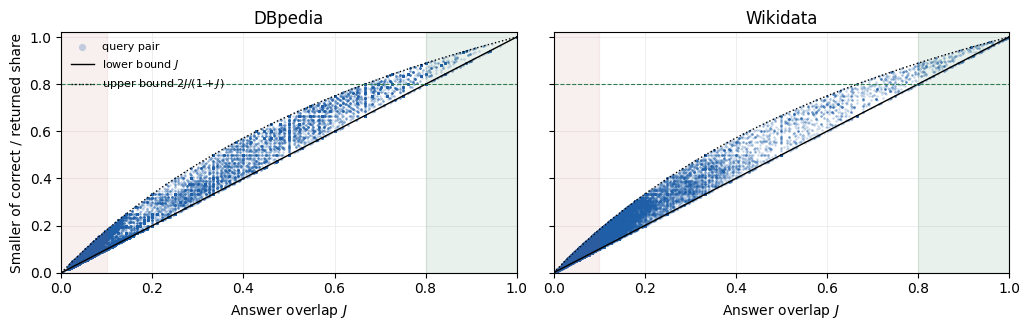

graph,DBpedia,Wikidata
positives: min of smaller share,0.800,0.800
positives: median of smaller share,1.000,1.000
positives: % with both shares = 1,81.670,80.156
negatives (J>0): max of smaller share,0.182,0.182
negatives (J>0): % where one answer mostly contains the other (larger share >= 0.5),42.432,22.355


In [5]:
rows = []
fig, axes = plt.subplots(1, len(PAIRS), figsize=(5.2 * len(PAIRS), 3.4), sharey=True)
rng = np.random.default_rng(0)
x = np.linspace(0, 1, 201)
for ax, (g, p) in zip(np.atleast_1d(axes), PAIRS.items()):
    I = p.inter
    a, b = p.sizes[p.i], p.sizes[p.j]
    worst = I / np.maximum(a, b)             # smaller of the two shares
    best = I / np.minimum(a, b)              # larger of the two shares
    pos, neg = p.J >= POS_MIN, p.J <= NEG_MAX
    assert np.all(worst >= p.J - 1e-9) and np.all(worst <= 2 * p.J / (1 + p.J) + 1e-9)
    rows.append({"graph": GRAPH_NAME[g],
                 "positives: min of smaller share": worst[pos].min(),
                 "positives: median of smaller share": np.median(worst[pos]),
                 "positives: % with both shares = 1": 100 * np.mean(worst[pos] >= 1 - 1e-12),
                 "negatives (J>0): max of smaller share": worst[neg].max() if neg.any() else np.nan,
                 "negatives (J>0): % where one answer mostly contains the other (larger share >= 0.5)":
                     100 * np.mean(best[neg] >= 0.5) if neg.any() else np.nan})
    k = rng.choice(len(worst), size=min(len(worst), 60000), replace=False)
    ax.scatter(p.J[k], worst[k], s=3, alpha=0.25, color=COL["pairs"], lw=0, rasterized=True, label="query pair")
    ax.plot(x, x, color="black", lw=1, label="lower bound $J$")
    ax.plot(x, 2 * x / (1 + x), color="black", lw=1, ls=":", label="upper bound $2J/(1+J)$")
    ax.axvspan(0, NEG_MAX, color=COL["neg"], alpha=0.08)
    ax.axvspan(POS_MIN, 1, color=COL["pos"], alpha=0.10)
    ax.axhline(POS_MIN, color=COL["pos"], lw=0.8, ls="--")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_xlabel("Answer overlap $J$")
    ax.set_title(GRAPH_NAME[g])
    ax.grid(color="0.92", lw=0.6); ax.set_axisbelow(True)
np.atleast_1d(axes)[0].set_ylabel("Smaller of correct / returned share")
np.atleast_1d(axes)[0].legend(loc="upper left", fontsize=8, frameon=False, markerscale=3)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"fig_reuse_guarantee.{ext}", dpi=200, bbox_inches="tight")
plt.show()
reuse = pd.DataFrame(rows).set_index("graph").round(3)
reuse.to_csv(OUT / "reuse_guarantee.csv")
reuse.T

## 4. How much do the labels change under other thresholds?

For every positive cutoff $\tau_+$ we count positive pairs, queries with at least one positive (possible anchors),
and the positive components. The components matter because splits are made by component: a lower $\tau_+$ joins
loosely related queries into large components, which makes component-disjoint splits coarse.
For every negative cutoff $\tau_-$ we count negatives and the share that still share rows with the anchor (the hard negatives).
Cells that need $J$ values in the unlabeled range are empty in `rq3` mode.

In [6]:
def pos_stats(p: Pairs, t: float) -> dict:
    if not p.known(min(t, 1.0), 1.0):
        return {"tau+": t, "positive pairs": np.nan, "queries with a positive": np.nan,
                "components (size>1)": np.nan, "largest component": np.nan,
                "% positives with J=1": np.nan, "mean J of positives": np.nan}
    m = p.J >= t - 1e-12
    n = p.n_queries
    G = sparse.coo_matrix((np.ones(m.sum()), (p.i[m], p.j[m])), shape=(n, n))
    k, lab = connected_components(G, directed=False)
    size = np.bincount(lab)
    return {"tau+": t, "positive pairs": int(m.sum()),
            "queries with a positive": int(len(np.unique(np.r_[p.i[m], p.j[m]]))),
            "components (size>1)": int((size > 1).sum()), "largest component": int(size.max()),
            "% positives with J=1": 100 * float(np.mean(p.J[m] >= 1)) if m.any() else np.nan,
            "mean J of positives": float(p.J[m].mean()) if m.any() else np.nan}


def neg_stats(p: Pairs, t: float) -> dict:
    if not p.known(0.0, t):
        return {"tau-": t, "negative pairs": np.nan, "% negatives with J>0": np.nan,
                "queries with a hard negative": np.nan}
    m = (p.J > 0) & (p.J <= t + 1e-12)
    n_neg = p.n_zero + int(m.sum())
    return {"tau-": t, "negative pairs": n_neg, "% negatives with J>0": 100 * m.sum() / n_neg,
            "queries with a hard negative": int(len(np.unique(np.r_[p.i[m], p.j[m]])))}


POS_TAB = pd.concat({GRAPH_NAME[g]: pd.DataFrame([pos_stats(p, t) for t in POS_GRID]).set_index("tau+")
                     for g, p in PAIRS.items()})
NEG_TAB = pd.concat({GRAPH_NAME[g]: pd.DataFrame([neg_stats(p, t) for t in NEG_GRID]).set_index("tau-")
                     for g, p in PAIRS.items()})
for name, tab, base in (("positive", POS_TAB, POS_MIN), ("negative", NEG_TAB, NEG_MAX)):
    rel = tab.copy()
    for gname in rel.index.get_level_values(0).unique():
        ref = tab.loc[(gname, base)]
        for c in tab.columns:
            if c.startswith("%") or c.startswith("mean"):
                continue
            rel.loc[gname, c + " (x vs paper)"] = (tab.loc[gname, c] / ref[c]).values
    rel.to_csv(OUT / f"sensitivity_{name}.csv")
POS_TAB.to_csv(OUT / "sensitivity_positive_counts.csv")
NEG_TAB.to_csv(OUT / "sensitivity_negative_counts.csv")
display(POS_TAB.round(3))
NEG_TAB.round(3)

positive pairs  queries with a positive  components (size>1)  largest component  % positives with J=1  mean J of positives
         tau+                                                                                                                            
DBpedia  0.50          129239                     4682                  853               1520                29.190                0.713
         0.60           71576                     4680                 1013                310                52.706                0.872
         0.70           57368                     4676                 1048                242                65.760                0.928
         0.75           52620                     4676                 1064                209                71.693                0.946
         0.80           46192                     4674                 1103                161                81.670                0.971
         0.85           40475                     4339                 1058                123                93.206                0.993
         0.90           38434                     4091                 1031                115                98.155                0.999
         0.95           37810                     3906                 1018                115                99.775                1.000
         1.00           37725                     3836                 1000                115               100.000                1.000
Wikidata 0.50           32134                     8515                 2333                253                50.495                0.841
         0.60           26121                     8494                 2438                 86                62.119                0.913
         0.70           22852                     8458                 2511                 56                71.005                0.951
         0.75           21510                     8436                 2539                 52                75.435                0.965
         0.80           20243                     8418                 2585                 52                80.156                0.978
         0.85           18927                     8005                 2503                 52                85.729                0.988
         0.90           17936                     7641                 2431                 52                90.466                0.995
         0.95           16981                     7157                 2285                 52                95.554                0.999
         1.00           16226                     6525                 2058                 52               100.000                1.000

negative pairs  % negatives with J>0  queries with a hard negative
         tau-                                                                    
DBpedia  0.00        10488952                 0.000                             0
         0.02        10496358                 0.071                          1337
         0.05        10646673                 1.481                          2202
         0.10        10853600                 3.360                          2411
         0.15        10912290                 3.879                          2469
         0.20        10943002                 4.149                          2553
         0.30        10979880                 4.471                          2593
Wikidata 0.00        46280082                 0.000                             0
         0.02        46406622                 0.273                          6299
         0.05        46499690                 0.472                          6580
         0.10        46650477                 0.794                          6829
         0.15        46731393                 0.966                          6897
         0.20        46764387                 1.036                          6943
         0.30        46785826                 1.081                          6982

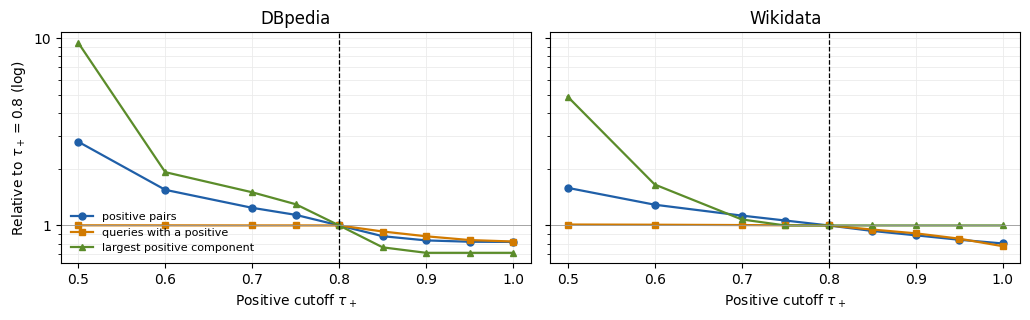

In [7]:
SENS_LINES = [("positive pairs", "pairs", "o", "positive pairs"),
              ("queries with a positive", "queries", "s", "queries with a positive"),
              ("largest component", "comp", "^", "largest positive component")]
import matplotlib.ticker
REL = pd.concat({GRAPH_NAME[g]: POS_TAB.loc[GRAPH_NAME[g]] / POS_TAB.loc[(GRAPH_NAME[g], POS_MIN)] for g in PAIRS})
SENS_LOG = bool(np.nanmax(REL[[c for c, *_ in SENS_LINES]].values) > 3)   # log scale only for a wide range
fig, axes = plt.subplots(1, len(PAIRS), figsize=(5.2 * len(PAIRS), 3.3), sharey=True)
for ax, g in zip(np.atleast_1d(axes), PAIRS):
    t = POS_TAB.loc[GRAPH_NAME[g]]
    for col, c, mk, lab in SENS_LINES:
        y = t[col] / t.loc[POS_MIN, col]
        ok = y.notna()
        ax.plot(np.array(POS_GRID)[ok.values], y[ok], marker=mk, ms=5, lw=1.6, color=COL[c], label=lab)
    ax.axvline(POS_MIN, color="black", ls="--", lw=0.9)
    ax.axhline(1, color="0.6", lw=0.6)
    if SENS_LOG:
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.set_xlim(min(POS_GRID) - 0.02, 1.02)
    ax.set_xlabel(r"Positive cutoff $\tau_+$")
    ax.set_title(GRAPH_NAME[g])
    ax.grid(color="0.92", lw=0.6, which="both"); ax.set_axisbelow(True)
np.atleast_1d(axes)[0].set_ylabel(r"Relative to $\tau_+=0.8$" + (" (log)" if SENS_LOG else ""))
np.atleast_1d(axes)[0].legend(fontsize=8, frameon=False, loc="lower left")
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"fig_sensitivity_positive.{ext}", dpi=200, bbox_inches="tight")
plt.show()

## 5. (optional) Do the retrieval gains depend on the 0.8 cutoff?

Without retraining, each zero-shot and fine-tuned checkpoint ranks all test queries (protocol C of the paper,
Table `tab:fullcollection`) and is scored with relevance $J \geq \tau$ for several $\tau$. Anchors with no relevant
query at a given $\tau$ are skipped. Enable with `LT_MODEL_CHECK=1` (needs `results/raw/<graph>/<model>/…` and
`PYTHONPATH=src`; DBpedia checkpoints were saved with transformers 5.x). Cutoffs below 0.8 need `full` mode.

In [8]:
def make_encoder(model_key: str, ckpt):
    """Returns texts -> L2-normalized numpy embeddings for one checkpoint (None = zero-shot)."""
    import torch
    from result_aware.config import load_model_config
    from result_aware.model import HFEmbeddingModel
    model = HFEmbeddingModel(load_model_config(model_key), device=DEVICE, checkpoint_path=ckpt)
    model.eval()

    def enc(texts):
        with torch.no_grad():
            e = model.encode(texts, batch_size=64).float().cpu().numpy()
        return e / np.linalg.norm(e, axis=1, keepdims=True)
    return enc


def test_collection(g: str):
    """Test queries of <graph>-test-rq3.json, anchors of <graph>-test.json, and the known J between test queries."""
    d = json.load(open(ROOT / "datasets" / f"{g}-splits" / f"{g}-test-rq3.json"))
    qs = sorted(d["queries"], key=lambda x: x["id"])
    texts = [q["query"] for q in qs]
    idx = {normalize_query(t): k for k, t in enumerate(texts)}
    recs = json.load(open(ROOT / "datasets" / f"{g}-splits" / f"{g}-test.json"))
    anchors = [idx[normalize_query(r["anchor_query"])] for r in recs]
    n = len(qs)
    Jm = np.zeros((n, n))
    p = PAIRS[g]
    if p.mode == "full":                        # every J between test queries, from the answer sets
        pos_of = {h: k for k, h in enumerate(p.hashes)}
        tid = np.full(p.n_queries, -1)
        for k, q in enumerate(qs):
            if q["query_hash"] in pos_of:
                tid[pos_of[q["query_hash"]]] = k
        a, b = tid[p.i], tid[p.j]
        m = (a >= 0) & (b >= 0)
        Jm[a[m], b[m]] = Jm[b[m], a[m]] = p.J[m]
        lowest = 0.0
    else:                                       # only J >= 0.8 is stored
        for a, b, j in d["positive_pairs"]:
            Jm[a, b] = Jm[b, a] = j
        lowest = POS_MIN
    return texts, anchors, Jm, lowest


def score(emb: np.ndarray, anchors, Jm, taus):
    S = emb @ emb.T
    out = []
    for t in taus:
        h1, mrr, used = [], [], 0
        for a in anchors:
            rel = Jm[a] >= t - 1e-12
            rel[a] = False
            if not rel.any():
                continue
            used += 1
            s = S[a].copy(); s[a] = -np.inf
            order = np.argsort(-s, kind="stable")
            r = np.flatnonzero(rel[order])[0] + 1
            h1.append(r == 1); mrr.append(1.0 / r)
        if used:
            out.append({"tau": t, "anchors": used, "hits@1": np.mean(h1), "mrr": np.mean(mrr)})
    return out


MODEL_TAB = None
if RUN_MODEL_CHECK:
    rows = []
    for g in GRAPHS:
        texts, anchors, Jm, lowest = test_collection(g)
        taus = [t for t in CHECK_REL if t >= lowest - 1e-12]
        raw = ROOT / "results" / "raw" / g
        for key in CHECK_MODELS:
            runs = [("zero-shot", None)] + [(f"seed_{s}", raw / key / "tuned" / f"seed_{s}" / "best_model")
                                            for s in CHECK_SEEDS]
            for tag, ckpt in runs:
                if ckpt is not None and not ckpt.exists():
                    print(f"  skip {g}/{key}/{tag}: no checkpoint")
                    continue
                enc = make_encoder(key, ckpt)
                for r in score(enc(texts), anchors, Jm, taus):
                    rows.append({"graph": GRAPH_NAME[g], "model": key,
                                 "run": "zero-shot" if ckpt is None else "fine-tuned", "seed": tag, **r})
                del enc
    MODEL_TAB = pd.DataFrame(rows)
    MODEL_TAB.to_csv(OUT / "fixed_encoder_cutoffs_runs.csv", index=False)
    agg = (MODEL_TAB.groupby(["graph", "model", "run", "tau"])[["anchors", "hits@1", "mrr"]]
           .agg(["mean", "std"]).round(4))
    agg.to_csv(OUT / "fixed_encoder_cutoffs.csv")
    display(agg)
else:
    print("Section 5 skipped (set LT_MODEL_CHECK=1 to run it).")

Section 5 skipped (set LT_MODEL_CHECK=1 to run it).


In [9]:
if MODEL_TAB is not None and len(MODEL_TAB):
    m = MODEL_TAB.groupby(["graph", "model", "run", "tau"])["hits@1"].mean().reset_index()
    graphs = list(m["graph"].unique())
    fig, axes = plt.subplots(1, len(graphs), figsize=(5.2 * len(graphs), 3.3), sharey=True)
    palette = ["#1f5fa8", "#d17a00", "#5b8c2a", "#8e3b8e", "#3a8f9a"]
    for ax, gname in zip(np.atleast_1d(axes), graphs):
        for c, key in zip(palette, m["model"].unique()):
            for run, ls in (("zero-shot", "--"), ("fine-tuned", "-")):
                s = m[(m.graph == gname) & (m.model == key) & (m.run == run)]
                ax.plot(s["tau"], s["hits@1"], ls=ls, marker="o", ms=4, color=c,
                        label=f"{key} ({run})")
        ax.axvline(POS_MIN, color="black", ls=":", lw=0.9)
        ax.set_xlabel(r"Relevance cutoff $J\geq\tau$"); ax.set_title(gname)
        ax.grid(color="0.92", lw=0.6); ax.set_axisbelow(True)
    np.atleast_1d(axes)[0].set_ylabel("Hits@1 (full test collection)")
    np.atleast_1d(axes)[-1].legend(fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"fig_fixed_encoder_cutoffs.{ext}", dpi=200, bbox_inches="tight")
    plt.show()

## 6. Export for the paper

* `labelthresholds_numbers.tex`: one `\newcommand` per number used in the appendix text. Numbers that need `full`
  mode are typeset in red (`\hp{...}`) when only `rq3` data was available.
* `labelthresholds.tex`: the appendix figure (pgfplots, same style as `riskcov.tex`): the $J$ distribution and the
  positive-cutoff sensitivity for both graphs.

In [10]:
def fmt_int(x):
    return "{:,}".format(int(x)).replace(",", "{,}")


def fmt_pct(x, d=1):
    return f"{x:.{d}f}\\%"


def fmt_x(x):
    return f"{x:.2f}" if x < 10 else f"{x:.0f}"


MISSING = r"\hp{[full mode]}"
macros = {}
for g, p in PAIRS.items():
    G = {"dbpedia": "Db", "wikidata": "Wd"}[g]
    b, s, r = bands.loc[GRAPH_NAME[g]], summary.loc[GRAPH_NAME[g]], reuse.loc[GRAPH_NAME[g]]
    pt = POS_TAB.loc[GRAPH_NAME[g]]
    nt = NEG_TAB.loc[GRAPH_NAME[g]]
    ov = b["pairs"] - b["J = 0"]
    macros[f"lt{G}Pairs"] = fmt_int(b["pairs"])
    macros[f"lt{G}Zero"] = fmt_pct(s["% J=0"])
    macros[f"lt{G}Labeled"] = fmt_pct(s["% labeled"])
    macros[f"lt{G}MidAll"] = fmt_pct(s["% unlabeled (of all)"])
    macros[f"lt{G}MidOverlap"] = fmt_pct(s["% unlabeled (of J>0)"])
    macros[f"lt{G}PosJone"] = fmt_pct(s["% positives with J=1"], 0)
    macros[f"lt{G}PosBelowNine"] = fmt_pct(s["% positives with J<0.9"])
    macros[f"lt{G}NegHard"] = fmt_pct(s["% negatives with J>0"])
    macros[f"lt{G}NegContain"] = fmt_pct(r.iloc[4])
    near7 = b["0.7 <= J < 0.8"]
    macros[f"lt{G}NearSeven"] = MISSING if np.isnan(near7) else fmt_pct(100 * near7 / b["positives"])
    for t, name in ((0.7, "Seven"), (0.9, "Nine"), (1.0, "One")):
        v = pt.loc[t, "positive pairs"] / pt.loc[POS_MIN, "positive pairs"]
        macros[f"lt{G}PosRatio{name}"] = MISSING if np.isnan(v) else fmt_pct(100 * v, 0)
        c = pt.loc[t, "largest component"]
        macros[f"lt{G}Comp{name}"] = MISSING if np.isnan(c) else fmt_int(c)
    macros[f"lt{G}CompPaper"] = fmt_int(pt.loc[POS_MIN, "largest component"])
    for t, name in ((0.9, "Nine"), (1.0, "One")):
        v = pt.loc[t, "queries with a positive"] / pt.loc[POS_MIN, "queries with a positive"]
        macros[f"lt{G}Anchor{name}"] = MISSING if np.isnan(v) else fmt_pct(100 * v, 0)
    c = pt.loc[0.5, "largest component"]
    macros[f"lt{G}CompFive"] = MISSING if np.isnan(c) else fmt_int(c)
    macros[f"lt{G}Queries"] = fmt_int(p.n_queries)
    v = nt.loc[0.2, "% negatives with J>0"]
    macros[f"lt{G}NegHardTwo"] = MISSING if np.isnan(v) else fmt_pct(v)
    macros[f"lt{G}Scope"] = p.scope

numbers = ["% generated by scripts/analysis/label_thresholds.ipynb -- do not edit by hand",
           f"% modes: " + ", ".join(f"{g}={p.mode}" for g, p in PAIRS.items())]
numbers += [f"\\providecommand{{\\{k}}}{{}}\\renewcommand{{\\{k}}}{{{v}}}" for k, v in macros.items()]
(OUT / "labelthresholds_numbers.tex").write_text("\n".join(numbers) + "\n")
pd.Series(macros, name="value").to_frame()

,value
ltDbPairs,"11{,}169{,}901"
ltDbZero,93.9\%
ltDbLabeled,97.6\%
ltDbMidAll,2.4\%
ltDbMidOverlap,39.7\%
ltDbPosJone,82\%
ltDbPosBelowNine,16.8\%
ltDbNegHard,3.4\%
ltDbNegContain,42.4\%
ltDbNearSeven,24.2\%


In [11]:
def coords(xs, ys):
    return " ".join(f"({x:.4f},{y:.6g})" for x, y in zip(xs, ys) if y > 0 and np.isfinite(y))


def bars(color, xs, ys):
    pts = coords(xs, ys)
    return f"\\addplot[fill={color}, draw=white] coordinates {{{pts}}};" if pts else ""


def hist_axis(g, p, first):
    c, n_one = histogram(p)
    centers = EDGES[:-1] + BIN_W / 2
    left = EDGES[:-1]
    neg = left + BIN_W <= NEG_MAX + 1e-9
    pos = left >= POS_MIN - 1e-9
    mid = ~neg & ~pos
    ylabel = "ylabel={Query pairs}," if first else "ylabel={},"
    note = (f"\\node[anchor=north, font=\\tiny, align=center] at (axis cs:0.45,{max(c.max(), n_one) * 0.8:.4g}) "
            f"{{{fmt_int(p.n_mid_unknown)} pairs with\\\\$0.1<J<0.8$\\\\(values not stored)}};"
            if p.n_mid_unknown else "")
    return f"""\\begin{{axis}}[ltstyle, title={{{GRAPH_NAME[g]}}}, {ylabel}
  ymode=log, log origin=infty, xmin=0, xmax=1.025, ybar, bar width={BIN_W}, bar shift=0pt,
  xlabel={{Answer overlap $J$}}, xtick={{0,0.2,0.4,0.6,0.8,1}}, ltcut={{{NEG_MAX},{POS_MIN}}}]
{bars("ltneg", centers[neg], c[neg])}
{bars("ltmid", centers[mid], c[mid])}
{bars("ltpos", np.r_[centers[pos], 1.0 + BIN_W / 2], np.r_[c[pos], n_one])}
{note}
\\end{{axis}}"""


def sens_axis(g, first):
    t = POS_TAB.loc[GRAPH_NAME[g]]
    styles = {"positive pairs": "color=blue!70!black, mark=*",
              "queries with a positive": "color=orange!85!black, mark=square*",
              "largest component": "color=green!50!black, mark=triangle*"}
    plots = []
    for col, _, _, lab in SENS_LINES:
        y = (t[col] / t.loc[POS_MIN, col]).values
        plots.append(f"\\addplot[{styles[col]}, mark size=1.3pt] coordinates {{{coords(POS_GRID, y)}}};")
        if first:
            plots.append(f"\\addlegendentry{{{lab}}}")
    ylabel = "ylabel={Relative to $\\tau_+=0.8$}," if first else "ylabel={},"
    ymode = "ymode=log, log ticks with fixed point," if SENS_LOG else ""
    legend = ("legend to name=ltlegend, legend columns=3, "
              "legend style={font=\\scriptsize, draw=none, /tikz/every even column/.append style={column sep=8pt}},"
              if first else "")
    return f"""\\begin{{axis}}[ltstyle, title={{}}, {ylabel} {ymode} {legend}
  xmin={min(POS_GRID) - 0.02}, xmax=1.02, xlabel={{Positive cutoff $\\tau_+$}}, ltcut={{{POS_MIN}}}]
{chr(10).join(plots)}
\\end{{axis}}"""


gs = list(PAIRS)
row1 = "\\hfill\n".join(f"\\begin{{tikzpicture}}\n{hist_axis(g, PAIRS[g], k == 0)}\n\\end{{tikzpicture}}" for k, g in enumerate(gs))
row2 = "\\hfill\n".join(f"\\begin{{tikzpicture}}\n{sens_axis(g, k == 0)}\n\\end{{tikzpicture}}" for k, g in enumerate(gs))
scope_note = ("over all pairs of the retained queries"
              if all(p.mode == "full" for p in PAIRS.values())
              else "over all pairs of validation and test queries; exact values in $0.1<J<0.8$ are not stored, so cutoffs below $0.8$ are not shown")
tex = f"""% generated by scripts/analysis/label_thresholds.ipynb -- do not edit by hand
\\begin{{figure}}[htbp]
\\centering
\\pgfplotsset{{ltstyle/.style={{
  width=0.49\\textwidth, height=3.9cm,
  xlabel style={{font=\\scriptsize}}, ylabel style={{font=\\scriptsize}},
  tick label style={{font=\\scriptsize}}, title style={{font=\\small}},
  grid=major, grid style={{black!10}}}},
  ltcut/.style={{extra x ticks={{#1}}, extra x tick labels={{}},
    extra x tick style={{grid=major, major grid style={{dashed, black!70}}, major tick length=0pt}}}}}}
\\definecolor{{ltneg}}{{RGB}}{{178,68,58}}
\\definecolor{{ltmid}}{{RGB}}{{154,154,154}}
\\definecolor{{ltpos}}{{RGB}}{{47,125,79}}
{row1}

\\vspace{{2pt}}
{row2}

\\vspace{{1pt}}
\\ref{{ltlegend}}
\\caption{{Label thresholds. Top: answer overlap $J$ of all query pairs with $J>0$ (log scale), colored
by label: negative ($J\\leq{NEG_MAX}$), unlabeled, positive ($J\\geq{POS_MIN}$; the last bar is $J=1$).
Bottom: positive pairs, queries with at least one positive, and the largest positive component
for other positive cutoffs $\\tau_+$, relative to $\\tau_+=0.8${" (log scale)" if SENS_LOG else ""}. Counts are {scope_note}.}}
\\label{{fig:labelthresholds}}
\\end{{figure}}
"""
(OUT / "labelthresholds.tex").write_text(tex)
if PAPER_DIR is not None:
    for f in ("labelthresholds.tex", "labelthresholds_numbers.tex"):
        shutil.copy(OUT / f, PAPER_DIR / f)
    print("copied to", PAPER_DIR)
print("written:", sorted(x.name for x in OUT.iterdir()))

written: ['band_counts.csv', 'band_summary.csv', 'fig_jaccard_distribution.pdf', 'fig_jaccard_distribution.png', 'fig_reuse_guarantee.pdf', 'fig_reuse_guarantee.png', 'fig_sensitivity_positive.pdf', 'fig_sensitivity_positive.png', 'labelthresholds.tex', 'labelthresholds_numbers.tex', 'pairs_dbpedia.npz', 'pairs_wikidata.npz', 'reuse_guarantee.csv', 'sensitivity_negative.csv', 'sensitivity_negative_counts.csv', 'sensitivity_positive.csv', 'sensitivity_positive_counts.csv']
